# 07 — CV teleportation

The Braunstein-Kimble continuous-variable teleportation protocol
(Braunstein & Kimble, PRL **80**, 869 (1998)), built with `Circuit`'s
feedforward mechanism, and its fidelity as a function of resource
squeezing and channel loss.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvcircuit as cv

np.set_printoptions(precision=4, suppress=True)

## The protocol

Alice has an unknown state (mode 0) she wants to send to Bob. They share
an EPR pair (modes 1 and 2, entangled by two-mode squeezing). Alice mixes
her state with her half of the EPR pair on a 50/50 beamsplitter, measures
`x` on one output and `p` on the other, and sends the two classical
numbers to Bob. Bob displaces his half of the EPR pair by a combination of
those numbers -- and, in the limit of infinite squeezing, his mode becomes
an exact copy of Alice's input.

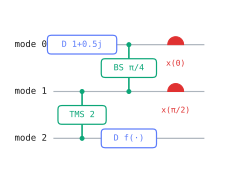

In [2]:
def teleportation_circuit(alpha_in, r, loss_eta=1.0):
    c = cv.Circuit(3)
    c.displace(alpha_in, mode=0)                      # Alice's state
    c.two_mode_squeeze(r, modes=(1, 2))                # shared EPR resource
    if loss_eta < 1.0:
        c.loss(loss_eta, mode=1)                       # lossy channel to Bob's half
    c.beamsplitter(np.pi / 4, modes=(0, 1))
    c.homodyne(0, angle=0.0, label="xA")
    c.homodyne(1, angle=np.pi / 2, label="pB")
    c.displace(lambda m: (m["xA"] + 1j * m["pB"]) / np.sqrt(2), mode=2)
    return c

alpha_in = 1.0 + 0.5j
c = teleportation_circuit(alpha_in, r=2.0)
c

In [3]:
final_state, records = c._execute(seed=0)
teleported = final_state.reduced([2])
print("measurement records:", {k: round(v, 4) for k, v in records.items()})
print("fidelity with the input state:", cv.fidelity(cv.coherent(alpha_in), teleported))

measurement records: {'xA': 8.4717, 'pB': -3.7413}
fidelity with the input state: 0.9559693068318507


## Fidelity vs. resource squeezing

More squeezing in the shared EPR resource -> a better teleportation
channel -> fidelity approaching 1.

Text(0.5, 1.0, 'teleporting a coherent state, alpha=(1+0.5j)')

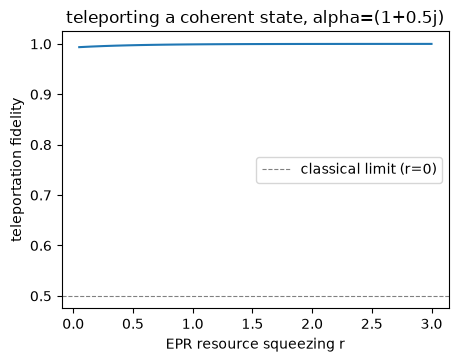

In [4]:
ideal = cv.coherent(alpha_in)
rs = np.linspace(0.05, 3.0, 30)
fidelities = []
for r in rs:
    final_state, _ = teleportation_circuit(alpha_in, r)._execute(seed=1)
    fidelities.append(cv.fidelity(ideal, final_state.reduced([2])))

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.plot(rs, fidelities)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8, label="classical limit (r=0)")
ax.set_xlabel("EPR resource squeezing r")
ax.set_ylabel("teleportation fidelity")
ax.legend()
ax.set_title(f"teleporting a coherent state, alpha={alpha_in}")

At `r=0` the "EPR resource" is just two independent vacuum modes, and the
protocol degenerates to a beamsplitter/homodyne measurement with no shared
entanglement -- the classical benchmark, fidelity 1/2 for a coherent
state with an unknown amplitude.

## Loss in the shared channel

Realistically, only one half of the EPR pair travels through a lossy
channel to Bob. Loss degrades the entanglement (see notebook 05) and
therefore the teleportation fidelity, even with a fixed, generous resource
squeezing.

Text(0.5, 1.0, 'fixed resource squeezing r=2.5')

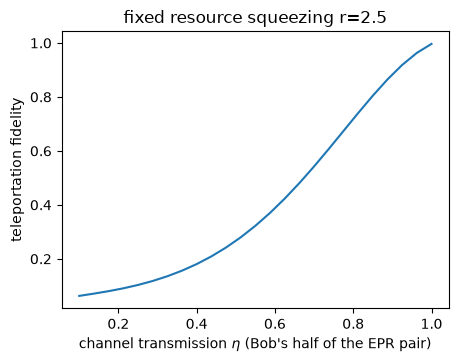

In [5]:
r_fixed = 2.5
etas = np.linspace(0.1, 1.0, 25)
fidelities_loss = []
for eta in etas:
    final_state, _ = teleportation_circuit(alpha_in, r_fixed, loss_eta=eta)._execute(seed=2)
    fidelities_loss.append(cv.fidelity(ideal, final_state.reduced([2])))

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.plot(etas, fidelities_loss)
ax.set_xlabel("channel transmission $\\eta$ (Bob's half of the EPR pair)")
ax.set_ylabel("teleportation fidelity")
ax.set_title(f"fixed resource squeezing r={r_fixed}")

## Averaging over many shots

Each teleportation run has random measurement outcomes but (for a fixed
input) a fidelity distribution that concentrates as squeezing grows.
Rather than compute fidelity per-shot (which needs each run's full
conditional state), a cheaper proxy is `Circuit.run()`'s measurement
statistics -- checking that Alice's homodyne outcomes really do follow the
expected Gaussian, as a sanity check on the whole pipeline.

In [6]:
c = teleportation_circuit(alpha_in, r=1.5)
result = c.run(shots=3000, seed=3)
print("mean(xA):", result.mean("xA"), " var(xA):", result.var("xA"))
print("mean(pB):", result.mean("pB"), " var(pB):", result.var("pB"))

mean(xA): 1.3858282865814247  var(xA): 5.636785175884728
mean(pB): 0.7449336673460781  var(pB): 5.648899766421659
